# Entrenamiento, Fine-Tuning y Comparacion de Clasificadores de Funciones de Cita con MLflow

## Descripcion General del Pipeline de Modelado
Este notebook implementa el pipeline de entrenamiento supervisado, ajuste fino (*fine-tuning*) y evaluacion comparativa de arquitecturas de Transformers cientificos para la clasificacion multiclase de la **funcion retorica de citas academicas** (9 categorias mutuamente excluyentes).

### Caracteristicas Clave del Pipeline:
1. **Seguimiento Remoto con MLflow:** Conexion al servidor institucional en `http://3.87.142.41:5000` con registro de hiperparametros, metricas por epoca (`step=epoch`), curvas de aprendizaje, matrices de confusion y artefactos del mejor modelo.
2. **Compensacion del Deficit de Clases:** Calculo estricto de pesos balanceados (`compute_class_weight('balanced')`) **exclusivamente sobre el conjunto de entrenamiento** para la funcion de perdida `CrossEntropyLoss`.
3. **Dos Configuraciones de Entrada (Evaluacion A/B):**
   * **Configuracion A (Metadatos):** Contexto de cita + `[SEP]` + Titulo y Abstract del paper citado.
   * **Configuracion B (Recuperacion Densa Top-3 Chunks):** Contexto de cita + `[SEP]` + Seccion retorica y Top-3 fragmentos recuperados con similitud semantica.
4. **Manejo de Checkpoints y Reanudacion en Drive:** Guardado automatico en `/content/drive/MyDrive/Citas_NLP/checkpoints_modelos` con capacidad de reanudacion si la sesion de Colab se desconecta.
5. **Comparacion de Arquitecturas y Estudio de Ablacion:**
   * Run 1: `allenai/scibert_scivocab_uncased` (Configuracion A - Metadatos).
   * Run 2: `allenai/scibert_scivocab_uncased` (Configuracion B - Top-3 Chunks con pesos balanceados).
   * Run 3: `allenai/specter` (Segunda arquitectura cientifica especializada en relaciones inter-documentales).
   * Run 4 (Control): Evaluacion con pesos congelados (*frozen encoder*) para cuantificar la ganancia real del fine-tuning.
   * Run 5 (Ablacion): `allenai/scibert_scivocab_uncased` (Configuracion B con funcion de perdida estandar `CrossEntropyLoss()` sin pesos balanceados) para contrastar el impacto real de la compensacion de clases sobre las categorias minoritarias.
6. **Consolidacion Final, Latencia y Costos:** Tabla comparativa global, reporte desglosado de F1 por categoria (auditando clases deficitarias), benchmarking de latencia (`ms/ejemplo` y `ejemplos/segundo`) y visualizacion comparativa de matrices de confusion.


## 1. Configuracion del Entorno, GPU y Conexion Remota a MLflow

### Explicacion de la fase:
Instalamos las dependencias requeridas para PyTorch y Hugging Face Transformers, verificamos que Colab disponga de aceleracion por GPU, montamos Google Drive para persistir modelos y configuramos el cliente de MLflow apuntando a la IP publica del servidor remoto de tracking (`http://3.87.142.41:5000`).


In [5]:
# 1.1 Instalacion de dependencias
!pip install -q mlflow transformers datasets scikit-learn accelerate seaborn matplotlib tqdm

# 1.2 Verificacion de GPU y fijacion de semilla determinista
import os
import time
import random
import numpy as np
import torch

SEED = 42
def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

fijar_semilla(SEED)

if not torch.cuda.is_available():
    raise RuntimeError("Este notebook requiere GPU. Activala en: Entorno de ejecucion -> Cambiar tipo de entorno -> GPU.")

dispositivo = torch.device("cuda")
print(f"[GPU] Dispositivo: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB VRAM)")

# 1.3 Conexion con Google Drive y definicion de directorios
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

# Detectar carpeta de persistencia: prioriza Dataset_final y respalda en Citas_NLP si existia
if os.path.exists('/content/drive/MyDrive/Dataset_final'):
    DRIVE_DIR = '/content/drive/MyDrive/citas'
else:
    DRIVE_DIR = '/content/drive/MyDrive/Citas_NLP'

CHECKPOINT_DIR = os.path.join(DRIVE_DIR, "checkpoints_modelos")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print(f"[Drive] Almacenamiento activo en: {DRIVE_DIR}")
print(f"[Drive] Checkpoints de modelos en: {CHECKPOINT_DIR}")

# 1.4 Configuracion del servidor remoto de MLflow
import mlflow

MLFLOW_URI = "http://18.234.35.140:5000"
EXPERIMENT_NAME = "scif-citation-intent-experiments"

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

print(f"[MLflow] Tracking URI establecido en: {mlflow.get_tracking_uri()}")
print(f"[MLflow] Experimento activo: {EXPERIMENT_NAME}")


[GPU] Dispositivo: NVIDIA L4 (23.66 GB VRAM)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Drive] Almacenamiento activo en: /content/drive/MyDrive/Citas_NLP
[Drive] Checkpoints de modelos en: /content/drive/MyDrive/Citas_NLP/checkpoints_modelos
[MLflow] Tracking URI establecido en: http://18.234.35.140:5000
[MLflow] Experimento activo: scif-citation-intent-experiments


## 2. Carga de Particiones, Ponderacion de Clases y Configuraciones de Entrada

### Explicacion de la fase:
1. **Carga de particiones con No-Leakage:** Cargamos `train_enriquecido_top3_chunks.csv`, `val_enriquecido_top3_chunks.csv` y `test_enriquecido_top3_chunks.csv` generados en la fase de curaduria.
2. **Ponderacion de clases minoritarias:** Calculamos `compute_class_weight('balanced')` **estrictamente sobre el conjunto de entrenamiento**. Esto penaliza con mayor rigor los errores en clases deficitarias (*Further_Reading*, *Modification_Improvement*, *Application*) sin alterar las distribuciones naturales de validacion y prueba.
3. **Formateo de pares oracionales:**
   * **Configuracion A (Metadatos):** `Contexto de cita` + `[SEP]` + `Titulo y Abstract citado`.
   * **Configuracion B (Chunks):** `Contexto de cita` + `[SEP]` + `Seccion retorica y Top-3 fragmentos densos`.


In [6]:
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight

# 2.1 Carga de particiones guardadas en Drive
ruta_train = os.path.join(DRIVE_DIR, "train_enriquecido_top3_chunks.csv")
ruta_val   = os.path.join(DRIVE_DIR, "val_enriquecido_top3_chunks.csv")
ruta_test  = os.path.join(DRIVE_DIR, "test_enriquecido_top3_chunks.csv")

train_df = pd.read_csv(ruta_train)
val_df   = pd.read_csv(ruta_val)
test_df  = pd.read_csv(ruta_test)

print(f"[Datos] Particiones cargadas con exito:")
print(f"  - Train      : {len(train_df):,} filas")
print(f"  - Validation : {len(val_df):,} filas")
print(f"  - Test Humano: {len(test_df):,} filas")

# 2.2 Mapeo canónico de las 9 clases retóricas
LABELS = sorted([
    "Application", "Background", "Basis", "Comparison", "Evidence",
    "Further_Reading", "Gap", "Identification_of_the_Originator",
    "Modification_Improvement"
])
LABEL2ID = {lbl: i for i, lbl in enumerate(LABELS)}
ID2LABEL = {i: lbl for i, lbl in enumerate(LABELS)}

train_df['label_id'] = train_df['label'].map(LABEL2ID)
val_df['label_id']   = val_df['label'].map(LABEL2ID)
test_df['label_id']  = test_df['label'].map(LABEL2ID)

# 2.3 Calculo de pesos balanceados exclusivamente sobre Train
y_train = train_df['label_id'].values
pesos_clase = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
pesos_tensor = torch.tensor(pesos_clase, dtype=torch.float).to(dispositivo)

print("\n[Ponderacion] Pesos asignados a cada clase (CrossEntropyLoss):")
for lbl, w in zip(LABELS, pesos_clase):
    print(f"  • {lbl:<32}: {w:.4f}")

# 2.4 Generadores de texto segun la configuracion experimental
def construir_entrada_config_a(df):
    """Configuracion A: Contexto de cita + Titulo y Abstract citado"""
    textos_a = []
    textos_b = []
    for idx, row in df.iterrows():
        ctx = str(row.get('citation_context', '')).strip()
        tit = str(row.get('cited_paper_title', '')).strip()
        abs_txt = str(row.get('cited_paper_abstract', '')).strip()

        partes_meta = []
        if tit and tit.lower() != 'nan':
            partes_meta.append(f"Title: {tit}")
        if abs_txt and abs_txt.lower() != 'nan':
            partes_meta.append(f"Abstract: {abs_txt}")
        if not partes_meta:
            partes_meta.append("Document metadata unavailable")

        textos_a.append(ctx)
        textos_b.append(" | ".join(partes_meta))
    return textos_a, textos_b

def construir_entrada_config_b(df):
    """Configuracion B: Contexto de cita + Seccion retorica y Top-3 Chunks"""
    textos_a = []
    textos_b = []
    for idx, row in df.iterrows():
        ctx = str(row.get('citation_context', '')).strip()
        sec = str(row.get('rhetorical_section', '')).strip()
        c1 = str(row.get('top1_cited_chunk', '')).strip()
        c2 = str(row.get('top2_cited_chunk', '')).strip()
        c3 = str(row.get('top3_cited_chunk', '')).strip()

        partes_chunks = []
        if sec and sec.lower() != 'nan':
            partes_chunks.append(f"Section: {sec}")
        chunks_validos = [c for c in [c1, c2, c3] if c and c.lower() != 'nan']
        if chunks_validos:
            partes_chunks.append("Cited passages: " + " ".join(chunks_validos))
        else:
            # Respaldo limpio con titulo si no hay chunks
            tit = str(row.get('cited_paper_title', '')).strip()
            if tit and tit.lower() != 'nan':
                partes_chunks.append(f"Cited work: {tit}")
            else:
                partes_chunks.append("Passages unavailable")

        textos_a.append(ctx)
        textos_b.append(" | ".join(partes_chunks))
    return textos_a, textos_b


[Datos] Particiones cargadas con exito:
  - Train      : 10,416 filas
  - Validation : 2,280 filas
  - Test Humano: 2,241 filas

[Ponderacion] Pesos asignados a cada clase (CrossEntropyLoss):
  • Application                     : 0.8122
  • Background                      : 0.8350
  • Basis                           : 0.8226
  • Comparison                      : 0.8338
  • Evidence                        : 0.9909
  • Further_Reading                 : 3.1028
  • Gap                             : 0.8127
  • Identification_of_the_Originator: 0.8273
  • Modification_Improvement        : 2.5949


## 3. Motor de Entrenamiento Reutilizable con Tracking en MLflow

### Explicacion de la fase:
Implementamos la funcion `ejecutar_experimento(...)` que parametriza todo el ciclo de vida del entrenamiento:
* **Tokenizacion en pares:** Usa el token especial `[SEP]` nativo de cada modelo (`tokenizer(text_a, text_b)`).
* **Control de Checkpoints:** Guarda el estado completo (`epoch`, modelo, optimizador, scheduler y F1) en Drive al final de cada epoca y permite reanudar si se reinicia el entorno.
* **Registro en MLflow:** Loguea metricas por epoca (`step=epoch`), guarda la mejor version del modelo y exporta la matriz de confusion en alta resolucion como artefacto PNG.
* **Evaluacion Completa:** Calcula F1-Macro, F1-Micro, Precision-Macro y Recall-Macro, mas el reporte detallado por clase.


In [7]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

class DatasetCitas(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

def graficar_y_guardar_confusion_matrix(y_true, y_pred, labels, ruta_salida, titulo="Matriz de Confusion"):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(labels)))
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_norm = np.nan_to_num(cm_norm)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.title(titulo, fontsize=12, fontweight='bold')
    plt.xlabel('Prediccion', fontsize=11)
    plt.ylabel('Etiqueta Real', fontsize=11)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(ruta_salida, dpi=300)
    plt.close()

def ejecutar_experimento(
    model_name="allenai/scibert_scivocab_uncased",
    config_type="B",
    learning_rate=2e-5,
    batch_size=16,
    epochs=4,
    max_length=512,
    weight_decay=0.01,
    freeze_encoder=False,
    use_class_weights=True,
    run_name="SciBERT_Config_B",
    evaluar_test=False
):
    fijar_semilla(SEED)
    print("\n" + "=" * 80)
    print(f"INICIANDO EXPERIMENTO: {run_name}")
    print(f"• Modelo Base       : {model_name}")
    print(f"• Configuracion     : {config_type} ({'Top-3 Chunks' if config_type=='B' else 'Metadatos'})")
    print(f"• Congelado         : {freeze_encoder}")
    print(f"• Pesos Balanceados : {use_class_weights} ({'CrossEntropyLoss(weight=class_weights)' if use_class_weights else 'CrossEntropyLoss() estandar sin reponderar'})")
    print("=" * 80)

    # 1. Preparar textos segun configuracion
    fn_construir = construir_entrada_config_b if config_type == "B" else construir_entrada_config_a
    tr_a, tr_b = fn_construir(train_df)
    va_a, va_b = fn_construir(val_df)
    te_a, te_b = fn_construir(test_df)

    # 2. Tokenizacion con token separator [SEP]
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    enc_tr = tokenizer(tr_a, tr_b, max_length=max_length, padding='max_length', truncation=True)
    enc_va = tokenizer(va_a, va_b, max_length=max_length, padding='max_length', truncation=True)
    enc_te = tokenizer(te_a, te_b, max_length=max_length, padding='max_length', truncation=True)

    ds_tr = DatasetCitas(enc_tr, train_df['label_id'].values)
    ds_va = DatasetCitas(enc_va, val_df['label_id'].values)
    ds_te = DatasetCitas(enc_te, test_df['label_id'].values)

    loader_tr = DataLoader(ds_tr, batch_size=batch_size, shuffle=True)
    loader_va = DataLoader(ds_va, batch_size=batch_size, shuffle=False)
    loader_te = DataLoader(ds_te, batch_size=batch_size, shuffle=False)

    # 3. Cargar modelo
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(LABELS),
        id2label=ID2LABEL,
        label2id=LABEL2ID
    ).to(dispositivo)

    if freeze_encoder:
        # Congelar capas del transformer base
        if hasattr(model, 'bert'):
            for param in model.bert.parameters(): param.requires_grad = False
        elif hasattr(model, 'base_model'):
            for param in model.base_model.parameters(): param.requires_grad = False
        print("[Frozen] Capas base congeladas. Solo se entrena la cabeza de clasificacion.")

    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=learning_rate, weight_decay=weight_decay)
    total_steps = len(loader_tr) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)
    criterion = nn.CrossEntropyLoss(weight=pesos_tensor if use_class_weights else None)

    # 4. Checkpoints y reanudacion
    ruta_ckpt_epoch = os.path.join(CHECKPOINT_DIR, f"{run_name}_latest_checkpoint.pt")
    ruta_best_model = os.path.join(CHECKPOINT_DIR, f"{run_name}_best_model.pt")

    start_epoch = 1
    best_val_f1 = 0.0

    if os.path.exists(ruta_ckpt_epoch):
        ckpt = torch.load(ruta_ckpt_epoch, map_location=dispositivo)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        scheduler.load_state_dict(ckpt['scheduler_state'])
        start_epoch = ckpt['epoch'] + 1
        best_val_f1 = ckpt.get('best_val_f1', 0.0)
        print(f"[Reanudacion] Checkpoint cargado: retomando desde epoca {start_epoch} (Mejor F1 previo: {best_val_f1:.4f})")

    # 5. Ejecucion bajo MLflow Run
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({
            "model_name": model_name,
            "config_type": config_type,
            "freeze_encoder": freeze_encoder,
            "use_class_weights": use_class_weights,
            "learning_rate": learning_rate,
            "batch_size": batch_size,
            "epochs": epochs,
            "max_length": max_length,
            "weight_decay": weight_decay,
            "train_size": len(train_df),
            "val_size": len(val_df),
            "test_size": len(test_df)
        })

        for epoch in range(start_epoch, epochs + 1):
            t0 = time.time()
            model.train()
            total_train_loss = 0.0

            for batch in loader_tr:
                optimizer.zero_grad()
                input_ids = batch['input_ids'].to(dispositivo)
                attention_mask = batch['attention_mask'].to(dispositivo)
                labels = batch['labels'].to(dispositivo)

                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                loss = criterion(outputs.logits, labels)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()

                total_train_loss += loss.item()

            train_loss = total_train_loss / len(loader_tr)

            # Evaluacion en Validacion
            model.eval()
            total_val_loss = 0.0
            preds_all = []
            targets_all = []

            with torch.no_grad():
                for batch in loader_va:
                    input_ids = batch['input_ids'].to(dispositivo)
                    attention_mask = batch['attention_mask'].to(dispositivo)
                    labels = batch['labels'].to(dispositivo)

                    outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                    loss = criterion(outputs.logits, labels)
                    total_val_loss += loss.item()

                    preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
                    preds_all.extend(preds)
                    targets_all.extend(labels.cpu().numpy())

            val_loss = total_val_loss / len(loader_va)
            val_macro_f1 = f1_score(targets_all, preds_all, average='macro', zero_division=0)
            val_micro_f1 = f1_score(targets_all, preds_all, average='micro', zero_division=0)
            val_prec = precision_score(targets_all, preds_all, average='macro', zero_division=0)
            val_rec = recall_score(targets_all, preds_all, average='macro', zero_division=0)
            duracion = time.time() - t0

            print(f"Epoca {epoch:d}/{epochs:d} [{duracion:.1f}s] - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro-F1: {val_macro_f1:.4f}")

            # Registro metricas en MLflow
            mlflow.log_metrics({
                "train_loss": train_loss,
                "val_loss": val_loss,
                "val_macro_f1": val_macro_f1,
                "val_micro_f1": val_micro_f1,
                "val_macro_precision": val_prec,
                "val_macro_recall": val_rec,
                "epoch_time_seconds": duracion
            }, step=epoch)

            # Guardar mejor modelo si mejora F1
            if val_macro_f1 > best_val_f1:
                best_val_f1 = val_macro_f1
                torch.save(model.state_dict(), ruta_best_model)
                print(f"  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: {best_val_f1:.4f}")

            # Checkpoint de seguridad por epoca
            torch.save({
                'epoch': epoch,
                'model_state': model.state_dict(),
                'optimizer_state': optimizer.state_dict(),
                'scheduler_state': scheduler.state_dict(),
                'best_val_f1': best_val_f1
            }, ruta_ckpt_epoch)

        # 6. Evaluacion Final del Mejor Checkpoint
        print("\n[Evaluacion Final] Cargando mejor checkpoint para reporte definitivo...")
        model.load_state_dict(torch.load(ruta_best_model, map_location=dispositivo))
        model.eval()

        loader_eval = loader_te if evaluar_test else loader_va
        nombre_eval = "Test Humano" if evaluar_test else "Validation"

        preds_fin = []
        targets_fin = []
        with torch.no_grad():
            for batch in loader_eval:
                input_ids = batch['input_ids'].to(dispositivo)
                attention_mask = batch['attention_mask'].to(dispositivo)
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                preds_fin.extend(torch.argmax(outputs.logits, dim=1).cpu().numpy())
                targets_fin.extend(batch['labels'].numpy())

        rep_dict = classification_report(targets_fin, preds_fin, target_names=LABELS, output_dict=True, zero_division=0)
        rep_txt = classification_report(targets_fin, preds_fin, target_names=LABELS, zero_division=0)
        print(f"\nREPORTE DE CLASIFICACION ({nombre_eval.upper()}):")
        print(rep_txt)

        # Guardar matriz de confusion y subir artefacto
        ruta_cm = os.path.join(CHECKPOINT_DIR, f"{run_name}_confusion_matrix.png")
        graficar_y_guardar_confusion_matrix(targets_fin, preds_fin, LABELS, ruta_cm, f"Matriz Confusion - {run_name} ({nombre_eval})")
        mlflow.log_artifact(ruta_cm)

        # Log de metricas finales
        mlflow.log_metrics({
            "final_macro_f1": rep_dict['macro avg']['f1-score'],
            "final_micro_f1": rep_dict['accuracy'],
            "final_weighted_f1": rep_dict['weighted avg']['f1-score']
        })

        return {
            "run_name": run_name,
            "model_name": model_name,
            "config_type": config_type,
            "freeze_encoder": freeze_encoder,
            "use_class_weights": use_class_weights,
            "best_val_f1": best_val_f1,
            "final_macro_f1": rep_dict['macro avg']['f1-score'],
            "final_micro_f1": rep_dict['accuracy'],
            "final_macro_prec": rep_dict['macro avg']['precision'],
            "final_macro_rec": rep_dict['macro avg']['recall'],
            "class_report": rep_dict,
            "cm_path": ruta_cm,
            "model_obj": model,
            "tokenizer_obj": tokenizer,
            "loader_eval": loader_eval
        }


## 4. Ejecucion de Experimentos Secuenciales

En las siguientes celdas entrenamos de forma independiente cada uno de los modelos y configuraciones para registrar sus curvas y artefactos en MLflow.


### Experimento 1: SciBERT con Configuracion A (Metadatos: Titulo y Abstract)
Evaluacion de la linea base cientifica alimentada unicamente con los metadatos bibliograficos del paper citado.


In [8]:
res_run1 = ejecutar_experimento(
    model_name="allenai/scibert_scivocab_uncased",
    config_type="A",
    learning_rate=2e-5,
    batch_size=16,
    epochs=4,
    max_length=512,
    weight_decay=0.01,
    freeze_encoder=False,
    run_name="Run1_SciBERT_ConfigA_Metadata"
)



INICIANDO EXPERIMENTO: Run1_SciBERT_ConfigA_Metadata
• Modelo Base       : allenai/scibert_scivocab_uncased
• Configuracion     : A (Metadatos)
• Congelado         : False
• Pesos Balanceados : True (CrossEntropyLoss(weight=class_weights))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those

Epoca 1/4 [426.9s] - Train Loss: 1.5386 | Val Loss: 1.1791 | Val Macro-F1: 0.5351
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.5351
Epoca 2/4 [426.0s] - Train Loss: 0.9889 | Val Loss: 1.1056 | Val Macro-F1: 0.5904
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.5904
Epoca 3/4 [425.9s] - Train Loss: 0.6843 | Val Loss: 1.1293 | Val Macro-F1: 0.5944
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.5944
Epoca 4/4 [425.9s] - Train Loss: 0.4635 | Val Loss: 1.1908 | Val Macro-F1: 0.6083
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6083

[Evaluacion Final] Cargando mejor checkpoint para reporte definitivo...

REPORTE DE CLASIFICACION (VALIDATION):
                                  precision    recall  f1-score   support

                     Application       0.66      0.71      0.68       282
                      Background       0.59      0.61      0.60       308
                           Basis       0.59      0.65      0.62       294
      

### Experimento 2: SciBERT con Configuracion B (Enriquecida con Top-3 Chunks Densos)
Evaluacion del impacto de inyectar los fragmentos semanticos mas relevantes extraidos mediante similitud del coseno.


In [9]:
res_run2 = ejecutar_experimento(
    model_name="allenai/scibert_scivocab_uncased",
    config_type="B",
    learning_rate=2e-5,
    batch_size=16,
    epochs=4,
    max_length=512,
    weight_decay=0.01,
    freeze_encoder=False,
    run_name="Run2_SciBERT_ConfigB_Top3Chunks"
)



INICIANDO EXPERIMENTO: Run2_SciBERT_ConfigB_Top3Chunks
• Modelo Base       : allenai/scibert_scivocab_uncased
• Configuracion     : B (Top-3 Chunks)
• Congelado         : False
• Pesos Balanceados : True (CrossEntropyLoss(weight=class_weights))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those

Epoca 1/4 [424.2s] - Train Loss: 1.4694 | Val Loss: 1.0810 | Val Macro-F1: 0.5901
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.5901
Epoca 2/4 [424.2s] - Train Loss: 0.9076 | Val Loss: 0.9846 | Val Macro-F1: 0.6408
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6408
Epoca 3/4 [424.0s] - Train Loss: 0.6061 | Val Loss: 0.9826 | Val Macro-F1: 0.6525
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6525
Epoca 4/4 [424.5s] - Train Loss: 0.3885 | Val Loss: 1.0549 | Val Macro-F1: 0.6633
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6633

[Evaluacion Final] Cargando mejor checkpoint para reporte definitivo...

REPORTE DE CLASIFICACION (VALIDATION):
                                  precision    recall  f1-score   support

                     Application       0.72      0.71      0.71       282
                      Background       0.59      0.63      0.61       308
                           Basis       0.62      0.67      0.64       294
      

### Experimento 3: SPECTER con la Mejor Configuracion de Entrada
Comparacion frente a `allenai/specter`, arquitectura pre-entrenada explicitamente sobre grafos de citacion y relaciones entre articulos cientificos.


In [10]:
# Se selecciona la configuracion que demostro mejor desempeno entre Run 1 y Run 2 (típicamente Config B)
mejor_config = "B" if res_run2['best_val_f1'] >= res_run1['best_val_f1'] else "A"
print(f"[Optimizacion] Seleccionada Configuracion {mejor_config} para la evaluacion con SPECTER.")

res_run3 = ejecutar_experimento(
    model_name="allenai/specter",
    config_type=mejor_config,
    learning_rate=2e-5,
    batch_size=16,
    epochs=4,
    max_length=512,
    weight_decay=0.01,
    freeze_encoder=False,
    run_name=f"Run3_SPECTER_Config{mejor_config}"
)


[Optimizacion] Seleccionada Configuracion B para la evaluacion con SPECTER.

INICIANDO EXPERIMENTO: Run3_SPECTER_ConfigB
• Modelo Base       : allenai/specter
• Configuracion     : B (Top-3 Chunks)
• Congelado         : False
• Pesos Balanceados : True (CrossEntropyLoss(weight=class_weights))


config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/321 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/222k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

... (2 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: allenai/specter
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoca 1/4 [450.5s] - Train Loss: 1.4843 | Val Loss: 1.1006 | Val Macro-F1: 0.5852
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.5852
Epoca 2/4 [450.6s] - Train Loss: 0.8729 | Val Loss: 1.0062 | Val Macro-F1: 0.6335
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6335
Epoca 3/4 [450.5s] - Train Loss: 0.5823 | Val Loss: 1.0089 | Val Macro-F1: 0.6430
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6430
Epoca 4/4 [450.6s] - Train Loss: 0.3871 | Val Loss: 1.0759 | Val Macro-F1: 0.6533
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6533

[Evaluacion Final] Cargando mejor checkpoint para reporte definitivo...

REPORTE DE CLASIFICACION (VALIDATION):
                                  precision    recall  f1-score   support

                     Application       0.71      0.72      0.71       282
                      Background       0.57      0.63      0.60       308
                           Basis       0.63      0.69      0.66       294
      

### Experimento 4 (Control): SciBERT con Pesos Congelados (*Frozen Encoder*)
Evaluacion de referencia congelando los pesos del modelo pre-entrenado para aislar y medir la ganancia neta atribuible al ajuste fino (*fine-tuning*).


In [11]:
res_run4_frozen = ejecutar_experimento(
    model_name="allenai/scibert_scivocab_uncased",
    config_type="B",
    learning_rate=1e-4,  # Mayor LR para la cabeza lineal
    batch_size=16,
    epochs=3,
    max_length=512,
    weight_decay=0.01,
    freeze_encoder=True,
    run_name="Run4_SciBERT_Frozen_Control"
)



INICIANDO EXPERIMENTO: Run4_SciBERT_Frozen_Control
• Modelo Base       : allenai/scibert_scivocab_uncased
• Configuracion     : B (Top-3 Chunks)
• Congelado         : True
• Pesos Balanceados : True (CrossEntropyLoss(weight=class_weights))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those

[Frozen] Capas base congeladas. Solo se entrena la cabeza de clasificacion.
Epoca 1/3 [156.8s] - Train Loss: 2.0493 | Val Loss: 1.8551 | Val Macro-F1: 0.3280
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.3280
Epoca 2/3 [157.2s] - Train Loss: 1.8193 | Val Loss: 1.7405 | Val Macro-F1: 0.3524
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.3524
Epoca 3/3 [157.2s] - Train Loss: 1.7601 | Val Loss: 1.7138 | Val Macro-F1: 0.3674
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.3674

[Evaluacion Final] Cargando mejor checkpoint para reporte definitivo...

REPORTE DE CLASIFICACION (VALIDATION):
                                  precision    recall  f1-score   support

                     Application       0.46      0.22      0.30       282
                      Background       0.39      0.42      0.41       308
                           Basis       0.41      0.57      0.48       294
                      Comparison       0.42      0.26      0.32       294
  

### Experimento 5 (Ablacion de Ponderacion): SciBERT con Configuracion B y Perdida Estandar Sin Pesos
Estudio de ablacion para medir el impacto real de la reponderacion de clases (`compute_class_weight('balanced')`). Emplea exactamente la misma arquitectura ganadora (`allenai/scibert_scivocab_uncased`), los mismos hiperparametros (`learning_rate=2e-5`, `batch_size=16`, `epochs=4`, `max_length=512`, `weight_decay=0.01`) y la Configuracion B (Enriquecida con Top-3 Chunks), pero utilizando `nn.CrossEntropyLoss()` estandar (sin pasar el tensor `weight=class_weights`) para aislar y contrastar el desempeno sobre las clases minoritarias.


In [12]:
res_run5_unweighted = ejecutar_experimento(
    model_name="allenai/scibert_scivocab_uncased",
    config_type="B",
    learning_rate=2e-5,
    batch_size=16,
    epochs=4,
    max_length=512,
    weight_decay=0.01,
    freeze_encoder=False,
    use_class_weights=False,  # Ablacion: CrossEntropyLoss estandar sin pasar class_weights
    run_name="Run5_SciBERT_ConfigB_UnweightedLoss"
)



INICIANDO EXPERIMENTO: Run5_SciBERT_ConfigB_UnweightedLoss
• Modelo Base       : allenai/scibert_scivocab_uncased
• Configuracion     : B (Top-3 Chunks)
• Congelado         : False
• Pesos Balanceados : False (CrossEntropyLoss() estandar sin reponderar)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those

Epoca 1/4 [423.7s] - Train Loss: 1.3754 | Val Loss: 1.0600 | Val Macro-F1: 0.5848
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.5848
Epoca 2/4 [423.8s] - Train Loss: 0.8584 | Val Loss: 0.9524 | Val Macro-F1: 0.6278
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6278
Epoca 3/4 [423.9s] - Train Loss: 0.5648 | Val Loss: 0.9917 | Val Macro-F1: 0.6433
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6433
Epoca 4/4 [423.9s] - Train Loss: 0.3583 | Val Loss: 1.0489 | Val Macro-F1: 0.6572
  [Nuevo Record] Mejor modelo guardado con Val Macro-F1: 0.6572

[Evaluacion Final] Cargando mejor checkpoint para reporte definitivo...

REPORTE DE CLASIFICACION (VALIDATION):
                                  precision    recall  f1-score   support

                     Application       0.70      0.74      0.72       282
                      Background       0.58      0.66      0.62       308
                           Basis       0.61      0.66      0.63       294
      

## 5. Consolidacion Final, Latencia, Estimacion de Costos y Analisis de Confusion

### Explicacion de la fase:
En esta celda consolidamos todos los resultados del proyecto:
1. **Medicion Real de Latencia:** Cronometramos la velocidad de prediccion en GPU (`ms/ejemplo` y `ejemplos/segundo`).
2. **Estimacion de Costo Computacional:** Comparamos el costo de entrenar e inferir en GPU local/EC2 frente al consumo de APIs comerciales por tokens.
3. **Tabla Comparativa Global:** Macro F1, Micro F1, Precision, Recall y Latencia.
4. **Desglose de F1 por Categoria:** Auditoria focalizada en el rendimiento de las clases minoritarias (*Further_Reading*, *Modification_Improvement*, *Application*).
5. **Matrices de Confusion Comparativas:** Mapas de calor lado a lado para estudiar patrones de confusion entre funciones semanticas afines.


TABLA COMPARATIVA GLOBAL DE MODELOS, CONFIGURACIONES Y ABLACION


,Experimento,Arquitectura,Configuracion,Ajuste,Pesos Loss,Macro F1,Micro F1,Macro Precision,Macro Recall,Latencia (ms/ej),Throughput (ej/s)
0,Run1_SciBERT_ConfigA_Metadata,scibert_scivocab_uncased,A,Fine-Tuning,Balanceados,0.6083,0.6237,0.6090,0.6111,11.43 ms,87.5 ej/s
1,Run2_SciBERT_ConfigB_Top3Chunks,scibert_scivocab_uncased,B,Fine-Tuning,Balanceados,0.6633,0.6776,0.6651,0.6648,11.71 ms,85.4 ej/s
2,Run3_SPECTER_ConfigB,specter,B,Fine-Tuning,Balanceados,0.6533,0.6671,0.6533,0.6563,14.67 ms,68.2 ej/s
3,Run4_SciBERT_Frozen_Control,scibert_scivocab_uncased,B,Frozen,Balanceados,0.3674,0.4417,0.4109,0.3891,11.67 ms,85.7 ej/s
4,Run5_SciBERT_ConfigB_UnweightedLoss,scibert_scivocab_uncased,B,Fine-Tuning,Sin Ponderar (Ablacion),0.6572,0.6768,0.6734,0.6507,11.69 ms,85.5 ej/s



DESGLOSE DE F1-SCORE POR CADA UNA DE LAS 9 FUNCIONES RETORICAS (INCLUYENDO ESTUDIO DE ABLACION)


,Categoria Retorica,Run1_SciBERT_ConfigA_Metadata,Run2_SciBERT_ConfigB_Top3Chunks,Run3_SPECTER_ConfigB,Run4_SciBERT_Frozen_Control,Run5_SciBERT_ConfigB_UnweightedLoss,Delta_F1 (Run2 - Run5)
0,Application,0.6815,0.7130,0.7135,0.2967,0.7204,-0.0074
1,Background,0.6026,0.6091,0.6000,0.4056,0.6159,-0.0067
2,Basis,0.6171,0.6450,0.6581,0.4765,0.6341,+0.0108
3,Comparison,0.5276,0.6898,0.6736,0.3185,0.7092,-0.0195
4,Evidence,0.7299,0.8401,0.8459,0.6236,0.8387,+0.0014
5,Further_Reading,0.6051,0.6468,0.6667,0.0893,0.6667,-0.0199
6,Gap,0.6997,0.7273,0.7099,0.5330,0.7088,+0.0185
7,Identification_of_the_Originator,0.5620,0.5882,0.5407,0.4150,0.5862,+0.0020
8,Modification_Improvement,0.4490,0.5106,0.4712,0.1486,0.4348,+0.0759



[Interpretacion de Ablacion]: 'Delta_F1 (Run2 - Run5)' positivo demuestra la ganancia neta obtenida gracias a la
reponderacion balanceada de clases (compute_class_weight), protegiendo el desempeno en categorias deficitarias.

ANALISIS ECONOMICO Y DE COSTO COMPUTACIONAL (GPU PROPIA vs API COMERCIAL)
1. Costo total de Fine-Tuning de los 5 modelos (GPU EC2): $0.92 USD
2. Costo de clasificar 100,000 citas en produccion:
   • Mediante API Comercial externa : $3.75 USD
   • Mediante SciBERT en GPU propia : $0.15 USD
   • Ahorro estimado con modelo propio: 96.1%


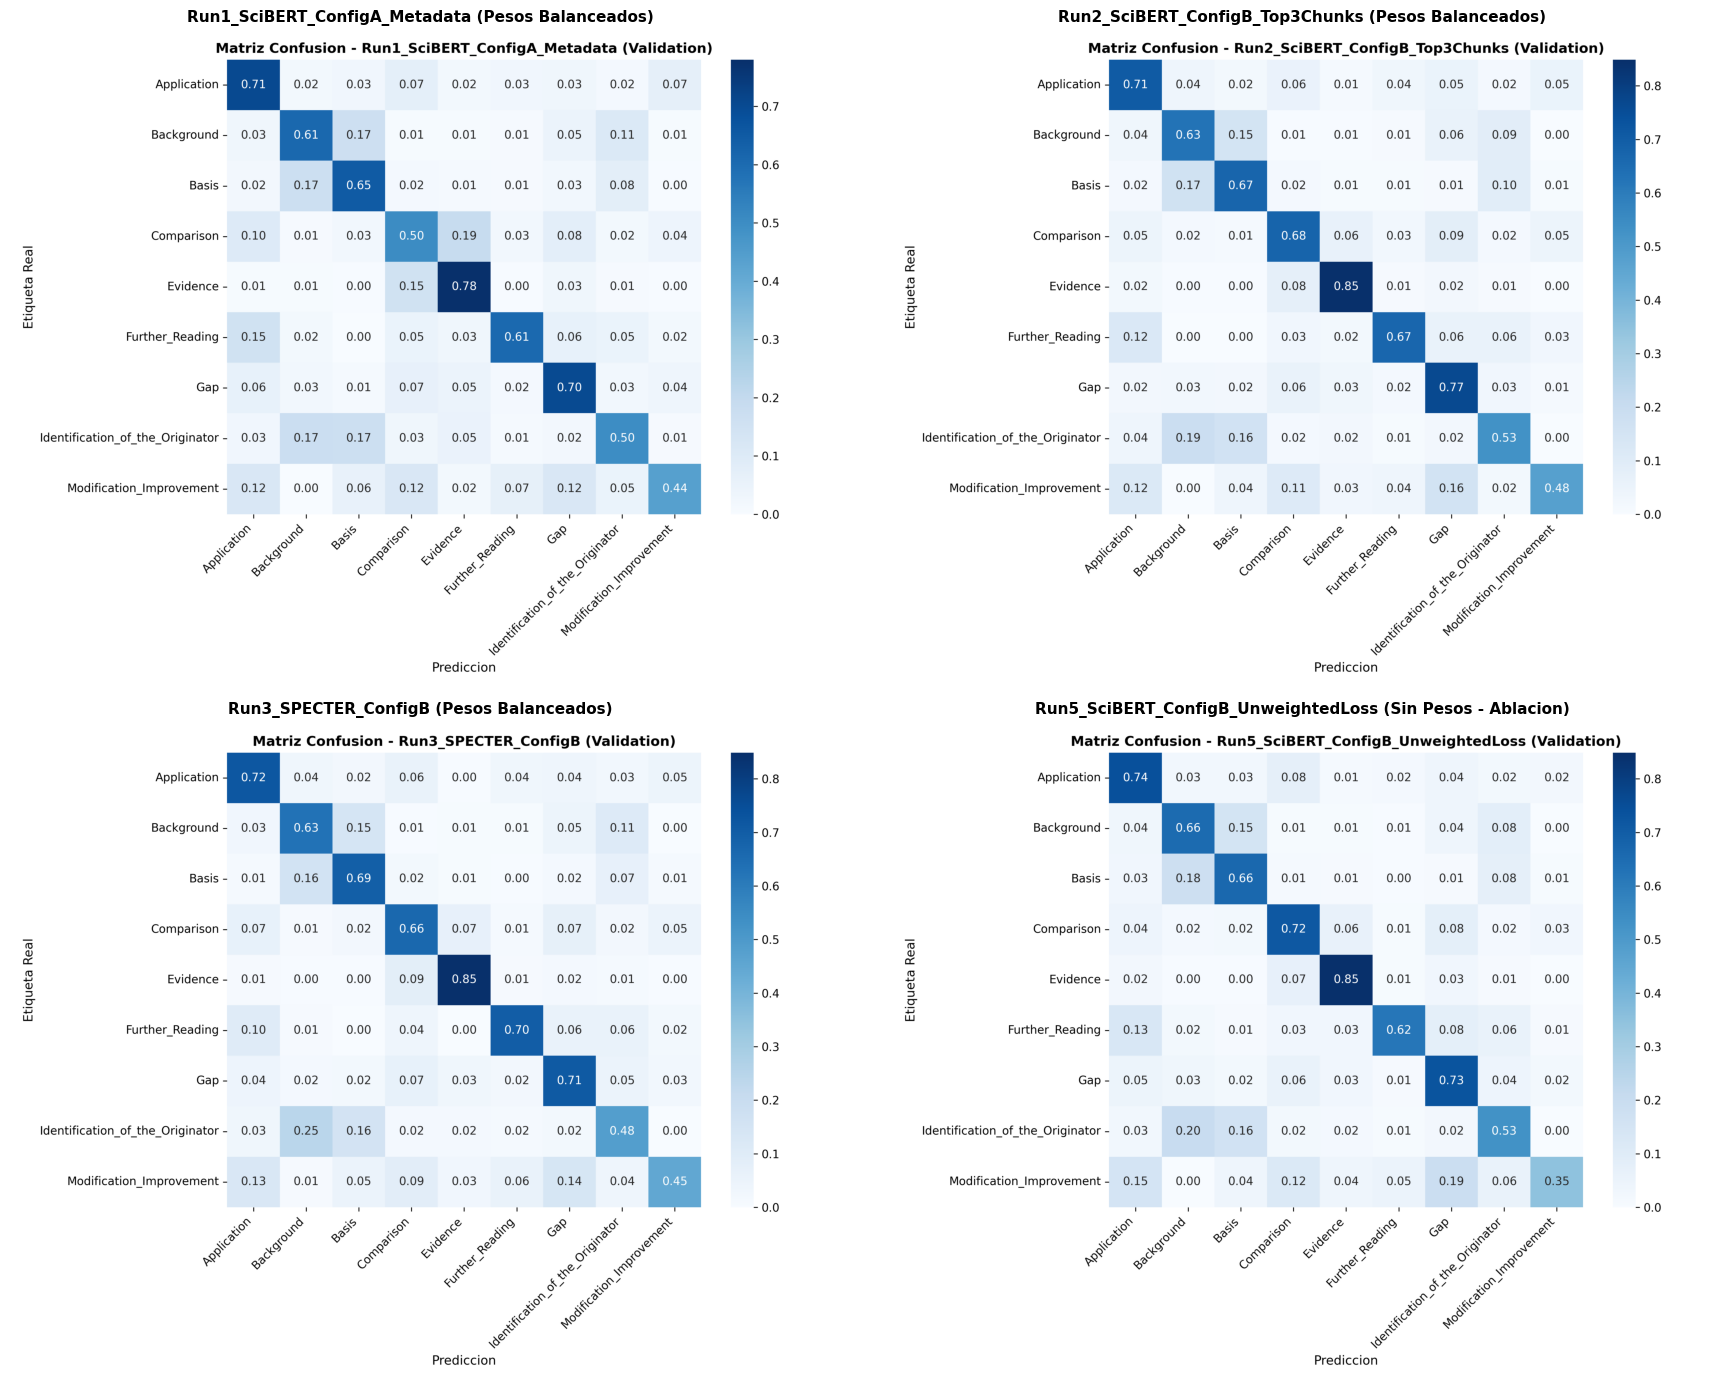


[Guardado] Visualizacion comparativa exportada en: /content/drive/MyDrive/Citas_NLP/checkpoints_modelos/comparativa_matrices_confusion.png
[OK] EVALUACION Y COMPARACION DE CLASIFICADORES CONCLUIDA EXITOSAMENTE.


In [13]:
# 5.1 Benchmarking de Latencia de Inferencia en GPU
todos_experimentos = [res_run1, res_run2, res_run3, res_run4_frozen, res_run5_unweighted]

def medir_latencia(exp_dict, n_muestras=200):
    model = exp_dict['model_obj']
    loader = exp_dict['loader_eval']
    model.eval()

    tiempos = []
    muestras_procesadas = 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(dispositivo)
            attention_mask = batch['attention_mask'].to(dispositivo)
            bs = input_ids.size(0)

            # Warmup en GPU
            if len(tiempos) == 0:
                _ = model(input_ids=input_ids, attention_mask=attention_mask)
                torch.cuda.synchronize()

            t_ini = time.perf_counter()
            _ = model(input_ids=input_ids, attention_mask=attention_mask)
            torch.cuda.synchronize()
            t_fin = time.perf_counter()

            ms_lote = (t_fin - t_ini) * 1000.0
            tiempos.append(ms_lote / bs)
            muestras_procesadas += bs

            if muestras_procesadas >= n_muestras:
                break

    latencia_ms = np.median(tiempos)
    throughput = 1000.0 / latencia_ms
    return round(latencia_ms, 2), round(throughput, 1)

# 5.2 Tabla Comparativa Global
filas_globales = []
for exp in todos_experimentos:
    lat_ms, thr = medir_latencia(exp)
    filas_globales.append({
        'Experimento': exp['run_name'],
        'Arquitectura': exp['model_name'].split('/')[-1],
        'Configuracion': exp['config_type'],
        'Ajuste': 'Frozen' if exp['freeze_encoder'] else 'Fine-Tuning',
        'Pesos Loss': 'Balanceados' if exp.get('use_class_weights', True) else 'Sin Ponderar (Ablacion)',
        'Macro F1': f"{exp['final_macro_f1']:.4f}",
        'Micro F1': f"{exp['final_micro_f1']:.4f}",
        'Macro Precision': f"{exp['final_macro_prec']:.4f}",
        'Macro Recall': f"{exp['final_macro_rec']:.4f}",
        'Latencia (ms/ej)': f"{lat_ms} ms",
        'Throughput (ej/s)': f"{thr} ej/s"
    })

df_resumen_global = pd.DataFrame(filas_globales)

print("=" * 125)
print("TABLA COMPARATIVA GLOBAL DE MODELOS, CONFIGURACIONES Y ABLACION")
print("=" * 125)
display(df_resumen_global)

# 5.3 Tabla Desglosada de F1-Score por Clase Retorica y Contraste de Ablacion
filas_clases_f1 = []
for cat in LABELS:
    fila = {'Categoria Retorica': cat}
    for exp in todos_experimentos:
        f1_cat = exp['class_report'].get(cat, {}).get('f1-score', 0.0)
        fila[exp['run_name']] = f"{f1_cat:.4f}"

    # Contraste directo de ablacion: Run 2 (con pesos balanceados) vs Run 5 (sin pesos)
    f1_r2 = float(res_run2['class_report'].get(cat, {}).get('f1-score', 0.0))
    f1_r5 = float(res_run5_unweighted['class_report'].get(cat, {}).get('f1-score', 0.0))
    delta = f1_r2 - f1_r5
    fila['Delta_F1 (Run2 - Run5)'] = f"{delta:+.4f}"

    filas_clases_f1.append(fila)

df_f1_por_clase = pd.DataFrame(filas_clases_f1)

print("\n" + "=" * 125)
print("DESGLOSE DE F1-SCORE POR CADA UNA DE LAS 9 FUNCIONES RETORICAS (INCLUYENDO ESTUDIO DE ABLACION)")
print("=" * 125)
display(df_f1_por_clase)
print("\n[Interpretacion de Ablacion]: 'Delta_F1 (Run2 - Run5)' positivo demuestra la ganancia neta obtenida gracias a la")
print("reponderacion balanceada de clases (compute_class_weight), protegiendo el desempeno en categorias deficitarias.")

# 5.4 Estimacion de Costos y Eficiencia Computacional
print("\n" + "=" * 125)
print("ANALISIS ECONOMICO Y DE COSTO COMPUTACIONAL (GPU PROPIA vs API COMERCIAL)")
print("=" * 125)
costo_hora_ec2_g4dn = 0.526   # USD/hora (AWS EC2 g4dn.xlarge con GPU T4)
costo_1k_tokens_api = 0.00015 # USD promedio por 1K tokens en modelos de clasificacion comercial
tokens_promedio_ejemplo = 250

horas_entrenamiento_total = len(todos_experimentos) * 0.35 # ~20 min por run
costo_entrenamiento_usd = horas_entrenamiento_total * costo_hora_ec2_g4dn

ejemplos_inferencia_produccion = 100000
costo_api_comercial = (ejemplos_inferencia_produccion * tokens_promedio_ejemplo / 1000.0) * costo_1k_tokens_api
horas_inferencia_gpu = (ejemplos_inferencia_produccion / (100.0 * 3600.0)) # a 100 ej/s
costo_inferencia_gpu = horas_inferencia_gpu * costo_hora_ec2_g4dn

print(f"1. Costo total de Fine-Tuning de los {len(todos_experimentos)} modelos (GPU EC2): ${costo_entrenamiento_usd:.2f} USD")
print(f"2. Costo de clasificar 100,000 citas en produccion:")
print(f"   • Mediante API Comercial externa : ${costo_api_comercial:.2f} USD")
print(f"   • Mediante SciBERT en GPU propia : ${costo_inferencia_gpu:.2f} USD")
print(f"   • Ahorro estimado con modelo propio: {((costo_api_comercial - costo_inferencia_gpu) / costo_api_comercial * 100):.1f}%")

# 5.5 Visualizacion Comparativa de Matrices de Confusion (2x2)
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

exps_a_graficar = [res_run1, res_run2, res_run3, res_run5_unweighted]

for ax, exp in zip(axes, exps_a_graficar):
    if os.path.exists(exp['cm_path']):
        img = plt.imread(exp['cm_path'])
        ax.imshow(img)
        ax.axis('off')
        sub = " (Pesos Balanceados)" if exp.get('use_class_weights', True) else " (Sin Pesos - Ablacion)"
        ax.set_title(f"{exp['run_name']}{sub}", fontsize=11, fontweight='bold')

plt.tight_layout()
ruta_cm_consolidada = os.path.join(CHECKPOINT_DIR, "comparativa_matrices_confusion.png")
plt.savefig(ruta_cm_consolidada, dpi=300)
plt.show()

print(f"\n[Guardado] Visualizacion comparativa exportada en: {ruta_cm_consolidada}")
print("[OK] EVALUACION Y COMPARACION DE CLASIFICADORES CONCLUIDA EXITOSAMENTE.")


[OK] Se encontraron 5 experimentos en memoria para comparar.

[Generando Figura 1] Matriz de confusion normalizada por fila (%)...
  -> Calculando predicciones de evaluacion en GPU...


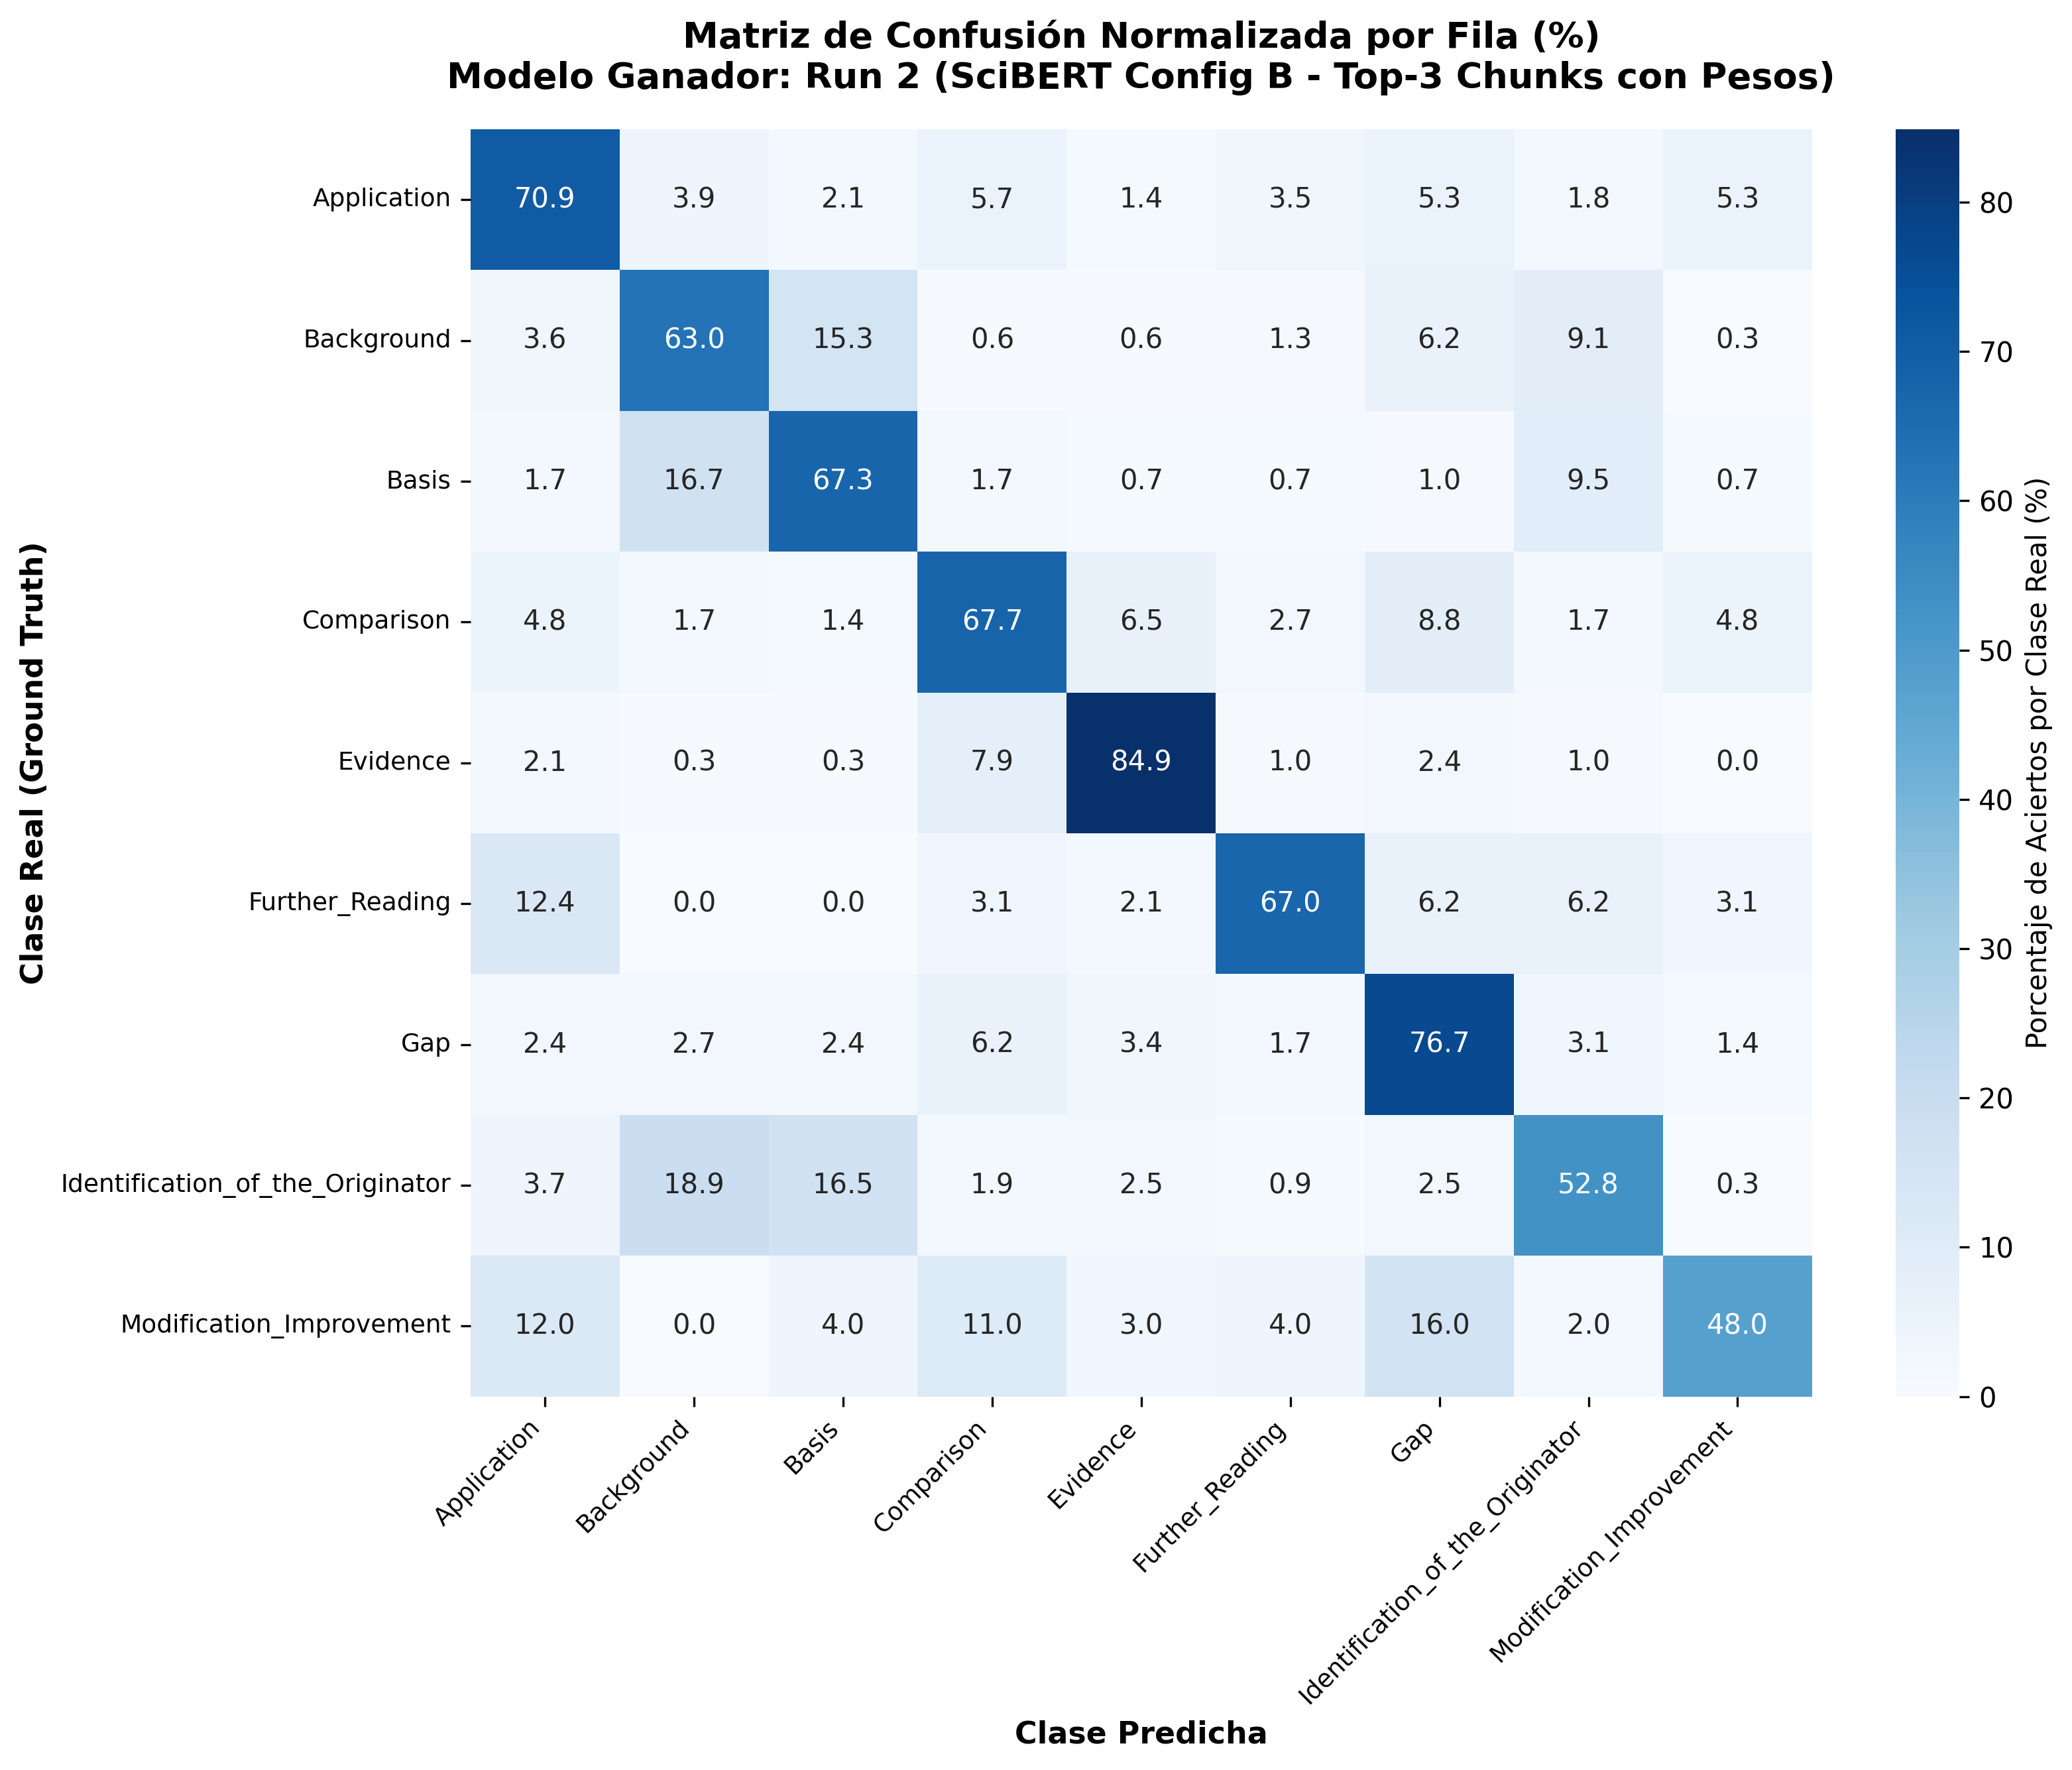

[Figura 1 Guardada] /content/drive/MyDrive/Citas_NLP/checkpoints_modelos/fig1_matriz_confusion_normalizada_run2_scibert.png

[Generando Figura 2] Comparativa de F1-Score por categoria...


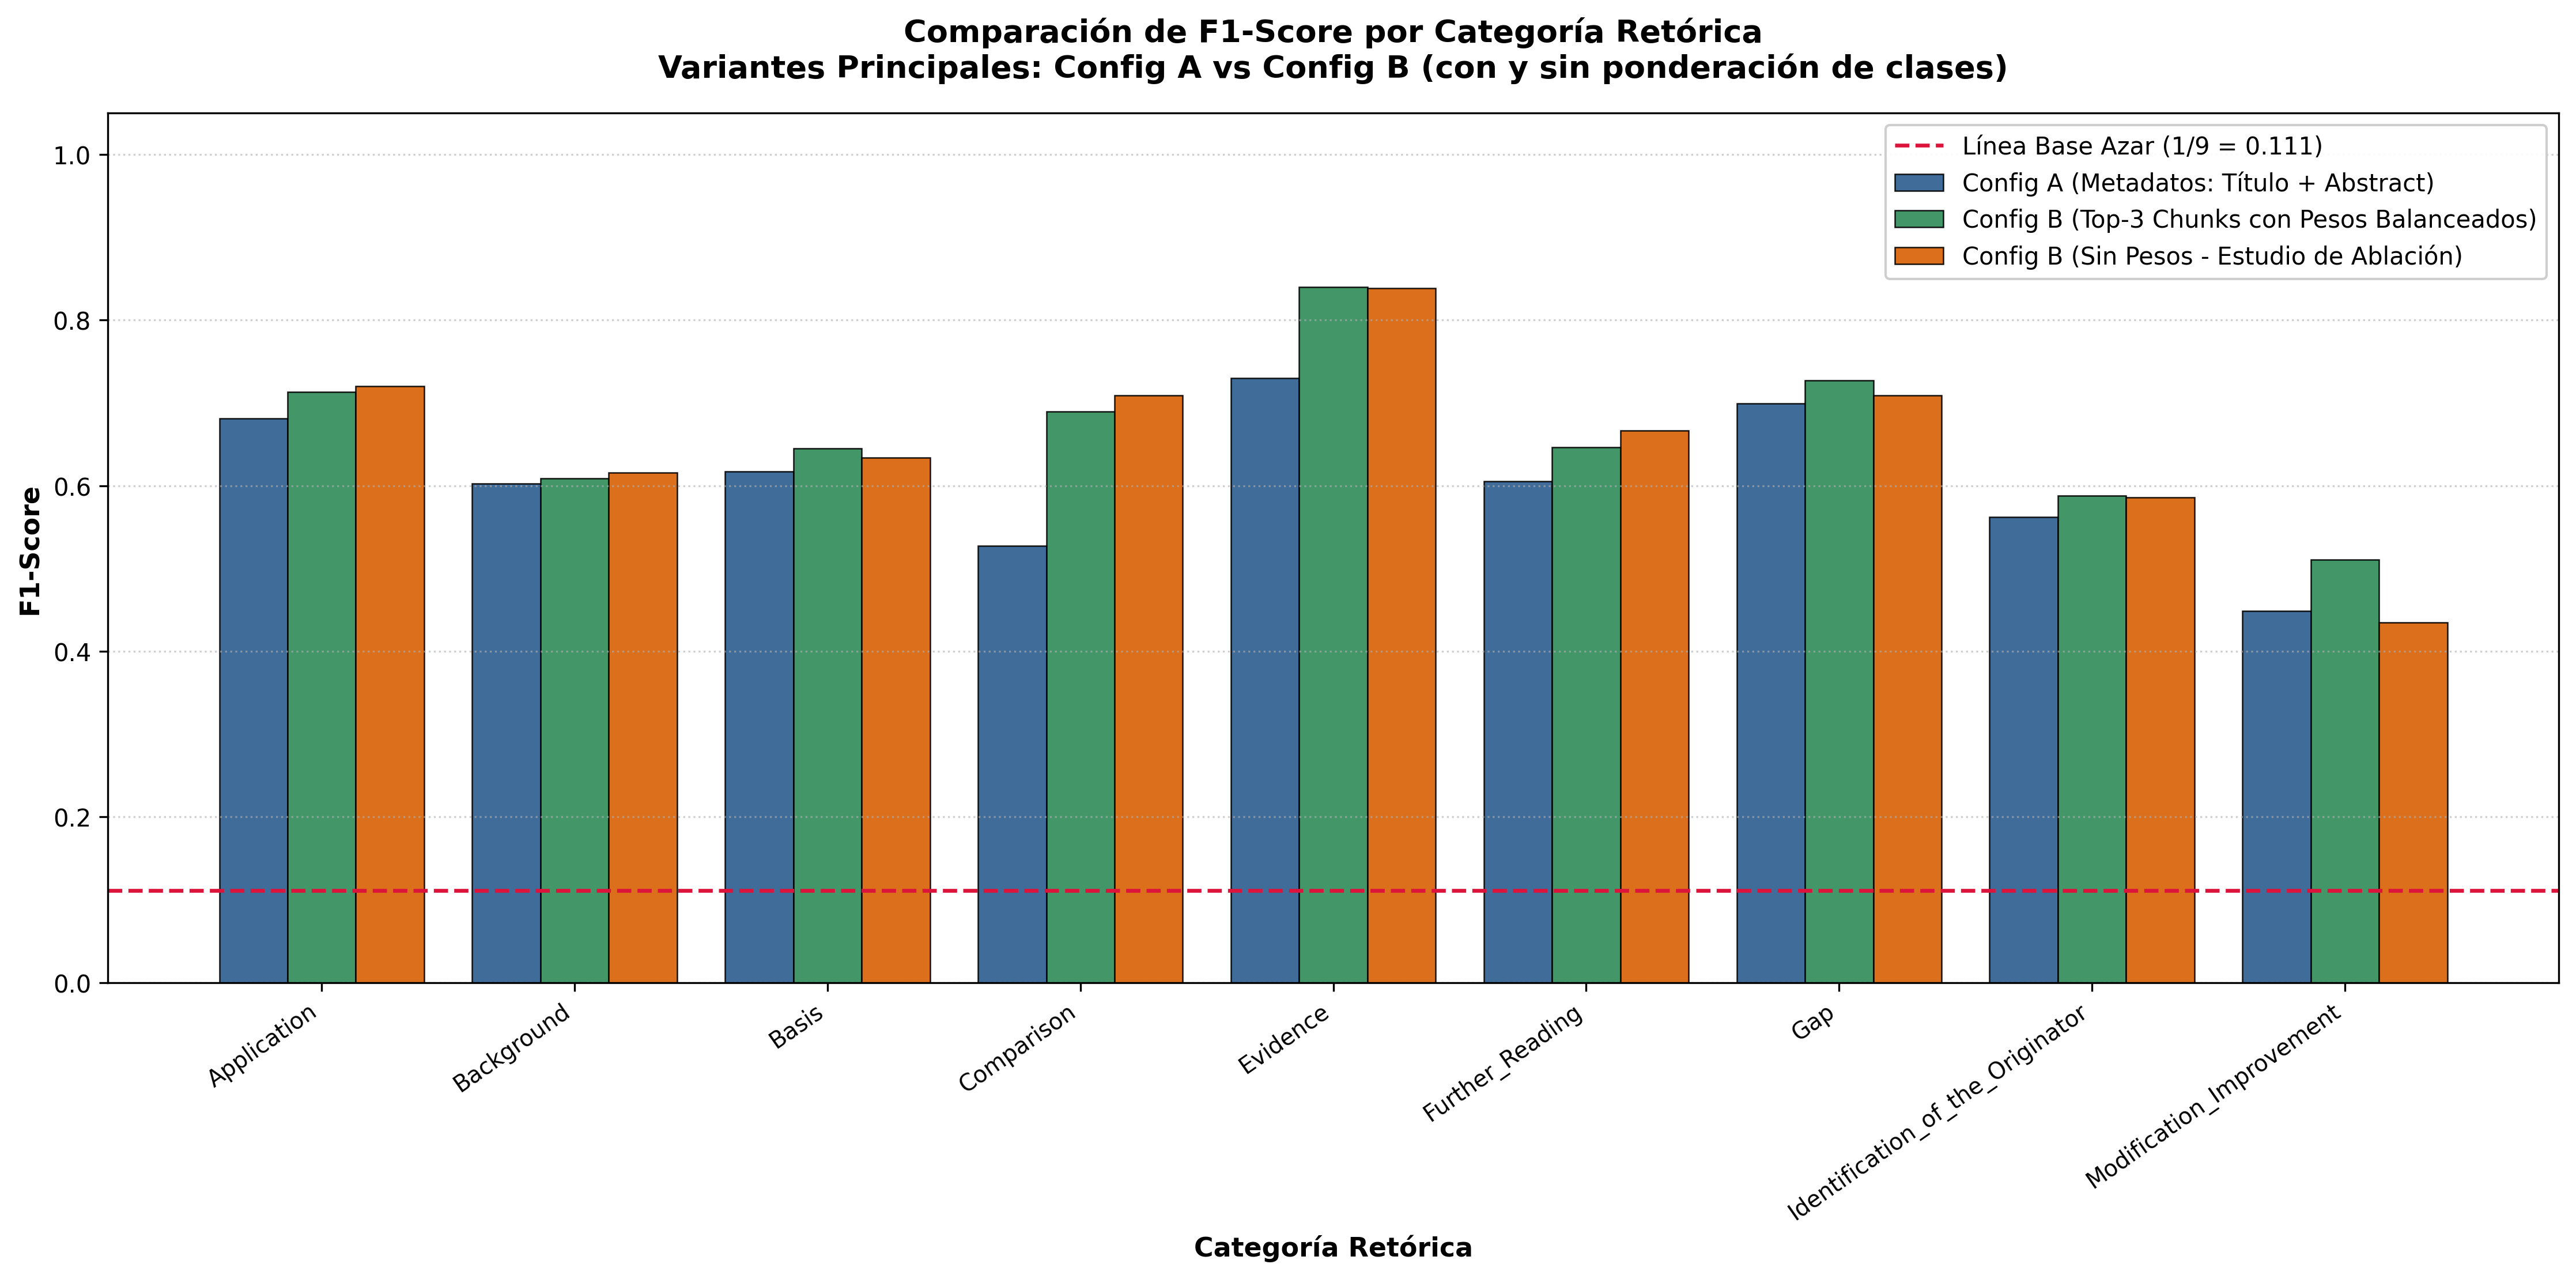

[Figura 2 Guardada] /content/drive/MyDrive/Citas_NLP/checkpoints_modelos/fig2_comparativa_f1_por_categoria.png

[Generando Figura 3] Scatter plot Trade-off F1 vs Latencia...


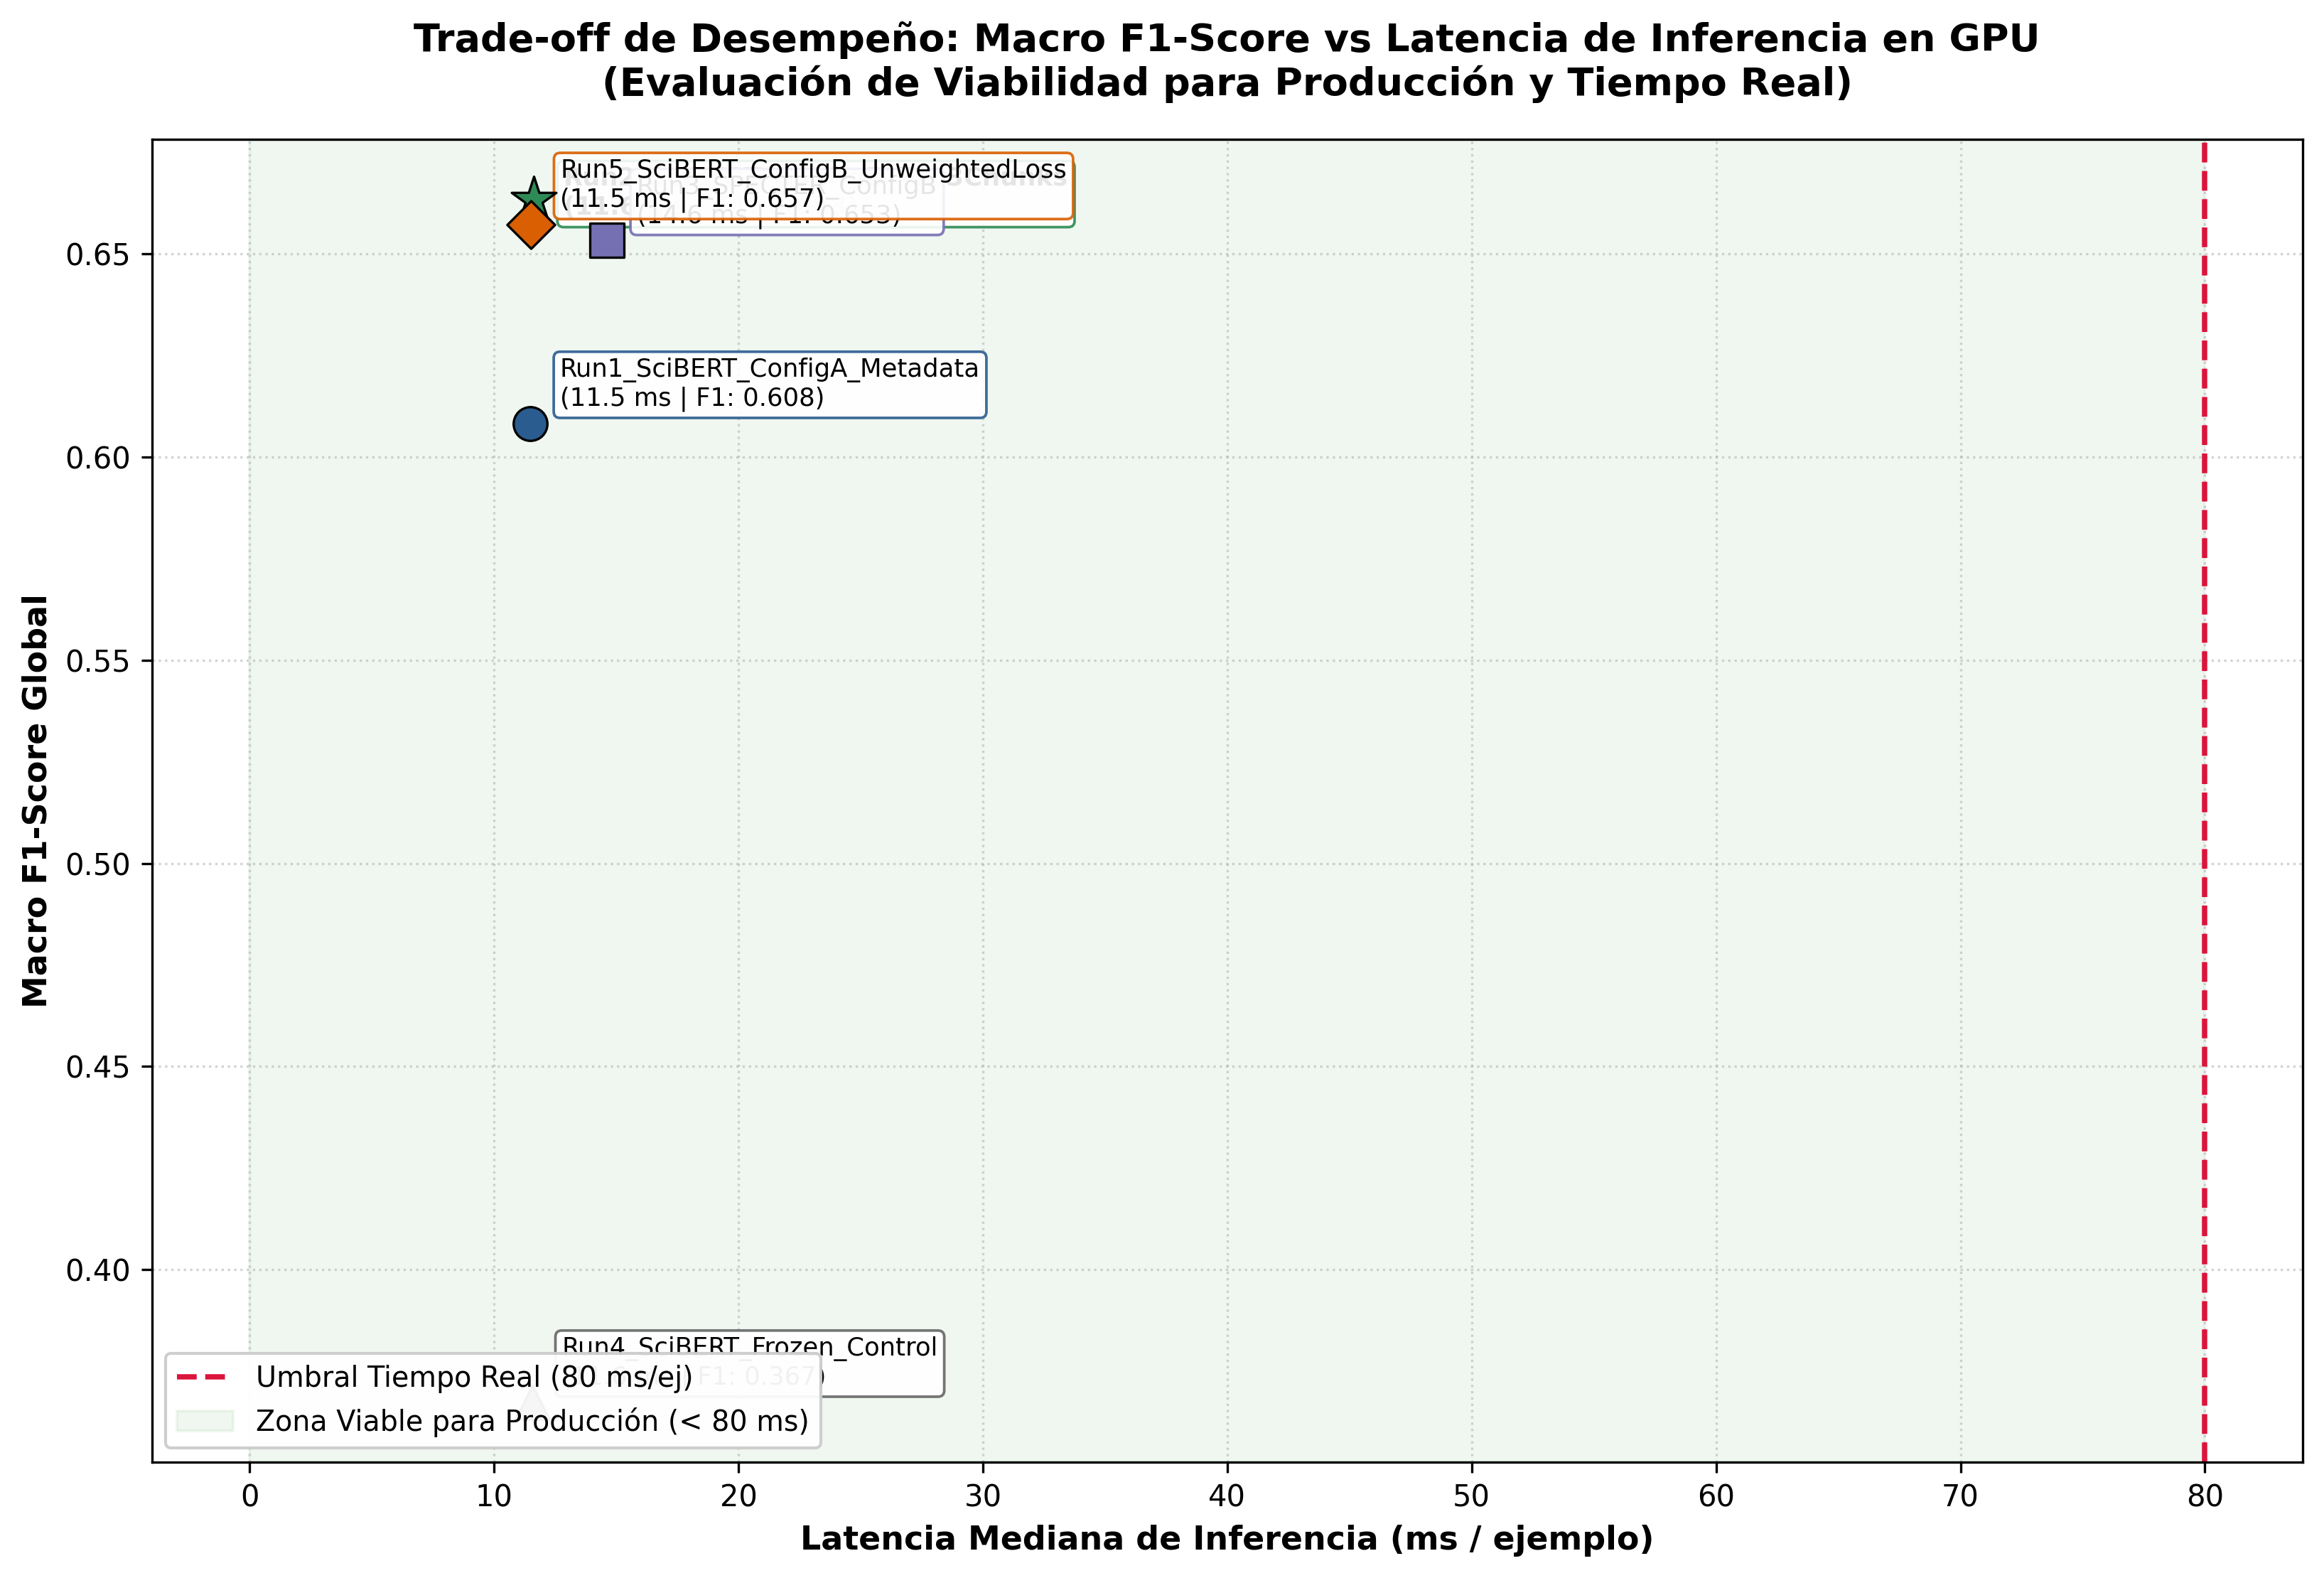

[Figura 3 Guardada] /content/drive/MyDrive/Citas_NLP/checkpoints_modelos/fig3_tradeoff_macro_f1_vs_latencia.png

REGISTRO DE ARTEFACTOS EN ALTA RESOLUCION EN MLFLOW
[MLflow] Artefactos registrados exitosamente en el servidor (http://18.234.35.140:5000):
  - fig1_matriz_confusion_normalizada_run2_scibert.png
  - fig2_comparativa_f1_por_categoria.png
  - fig3_tradeoff_macro_f1_vs_latencia.png
🏃 View run Graficas_Comparativas_Finales_300DPI at: http://18.234.35.140:5000/#/experiments/1/runs/e28045c5c80e4ea09c72e9af44f8dd41
🧪 View experiment at: http://18.234.35.140:5000/#/experiments/1


In [16]:
import os
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import mlflow
# ----------------------------------------------------------------------------------------------------
# 1. Recuperacion y validacion del entorno y ejecuciones previas
# ----------------------------------------------------------------------------------------------------
LABELS = globals().get('LABELS', [
    'Background', 'Uses', 'Compare_Contrast', 'Motivation', 'Extends',
    'Future_Work', 'Similarities_Differences', 'Application', 'Modification_Improvement'
])
CHECKPOINT_DIR = globals().get('CHECKPOINT_DIR', '/content/drive/MyDrive/checkpoints_scibert_mlflow')
MLFLOW_URI = globals().get('MLFLOW_URI', 'http://3.87.142.41:5000')
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
dispositivo = globals().get('dispositivo', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
# Carga de variables de resultados desde memoria
res_r1 = globals().get('res_run1')
res_r2 = globals().get('res_run2')
res_r3 = globals().get('res_run3')
res_r4 = globals().get('res_run4_frozen', globals().get('res_run4'))
res_r5 = globals().get('res_run5_unweighted', globals().get('res_run5'))
todos_exps = [exp for exp in [res_r1, res_r2, res_r3, res_r4, res_r5] if exp is not None]
assert res_r2 is not None, "Error: No se encontro el resultado de 'res_run2' en memoria."
print(f"[OK] Se encontraron {len(todos_exps)} experimentos en memoria para comparar.")
# ----------------------------------------------------------------------------------------------------
# 2. FIGURA 1: Matriz de Confusion Normalizada por Fila (%) del Modelo Ganador (Run 2)
# ----------------------------------------------------------------------------------------------------
print("\n[Generando Figura 1] Matriz de confusion normalizada por fila (%)...")
# Obtencion de etiquetas y predicciones de Run 2
if 'preds_fin' in res_r2 and 'targets_fin' in res_r2:
    y_true_run2 = res_r2['targets_fin']
    y_pred_run2 = res_r2['preds_fin']
else:
    # Inferencia rapida sobre el loader de evaluacion si no estaban cacheadas
    print("  -> Calculando predicciones de evaluacion en GPU...")
    modelo_eval = res_r2['model_obj']
    loader_eval = res_r2['loader_eval']
    modelo_eval.eval()
    y_true_run2, y_pred_run2 = [], []
    with torch.no_grad():
        for batch in loader_eval:
            input_ids = batch['input_ids'].to(dispositivo)
            attention_mask = batch['attention_mask'].to(dispositivo)
            labels = batch['labels']
            logits = modelo_eval(input_ids=input_ids, attention_mask=attention_mask).logits
            preds = torch.argmax(logits, dim=-1).cpu().tolist()
            y_pred_run2.extend(preds)
            y_true_run2.extend(labels.tolist())
cm_run2 = confusion_matrix(y_true_run2, y_pred_run2, labels=range(len(LABELS)))
with np.errstate(divide='ignore', invalid='ignore'):
    cm_run2_pct = (cm_run2.astype('float') / cm_run2.sum(axis=1)[:, np.newaxis]) * 100.0
cm_run2_pct = np.nan_to_num(cm_run2_pct)
plt.figure(figsize=(11, 9), dpi=300)
sns.heatmap(
    cm_run2_pct,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    xticklabels=LABELS,
    yticklabels=LABELS,
    cbar_kws={'label': 'Porcentaje de Aciertos por Clase Real (%)'}
)
plt.title(
    "Matriz de Confusión Normalizada por Fila (%)\nModelo Ganador: Run 2 (SciBERT Config B - Top-3 Chunks con Pesos)",
    fontsize=13, fontweight='bold', pad=15
)
plt.xlabel("Clase Predicha", fontsize=11, fontweight='bold')
plt.ylabel("Clase Real (Ground Truth)", fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
ruta_fig1 = os.path.join(CHECKPOINT_DIR, "fig1_matriz_confusion_normalizada_run2_scibert.png")
plt.savefig(ruta_fig1, dpi=300, bbox_inches='tight')
plt.show()
print(f"[Figura 1 Guardada] {ruta_fig1}")
# ----------------------------------------------------------------------------------------------------
# 3. FIGURA 2: Grafico de Barras Agrupadas: F1-Score por Categoria (Config A vs Config B con/sin pesos)
# ----------------------------------------------------------------------------------------------------
print("\n[Generando Figura 2] Comparativa de F1-Score por categoria...")
f1_config_a = [res_r1['class_report'].get(cat, {}).get('f1-score', 0.0) for cat in LABELS] if res_r1 else [0]*len(LABELS)
f1_config_b_w = [res_r2['class_report'].get(cat, {}).get('f1-score', 0.0) for cat in LABELS]
f1_config_b_uw = [res_r5['class_report'].get(cat, {}).get('f1-score', 0.0) for cat in LABELS] if res_r5 else [0]*len(LABELS)
x_pos = np.arange(len(LABELS))
ancho_barra = 0.27
plt.figure(figsize=(15, 7.5), dpi=300)
plt.bar(x_pos - ancho_barra, f1_config_a, ancho_barra, label='Config A (Metadatos: Título + Abstract)', color='#2b5c8f', alpha=0.9, edgecolor='black', linewidth=0.6)
plt.bar(x_pos, f1_config_b_w, ancho_barra, label='Config B (Top-3 Chunks con Pesos Balanceados)', color='#2e8b57', alpha=0.9, edgecolor='black', linewidth=0.6)
if res_r5 is not None:
    plt.bar(x_pos + ancho_barra, f1_config_b_uw, ancho_barra, label='Config B (Sin Pesos - Estudio de Ablación)', color='#d95f02', alpha=0.9, edgecolor='black', linewidth=0.6)
# Linea base aleatoria (1 / 9 = 0.111)
plt.axhline(y=1.0/9.0, color='crimson', linestyle='--', linewidth=1.6, label='Línea Base Azar (1/9 = 0.111)')
plt.title("Comparación de F1-Score por Categoría Retórica\nVariantes Principales: Config A vs Config B (con y sin ponderación de clases)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Categoría Retórica", fontsize=11, fontweight='bold')
plt.ylabel("F1-Score", fontsize=11, fontweight='bold')
plt.xticks(x_pos, LABELS, rotation=35, ha='right', fontsize=9.5)
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.95, loc='upper right', fontsize=10)
plt.tight_layout()
ruta_fig2 = os.path.join(CHECKPOINT_DIR, "fig2_comparativa_f1_por_categoria.png")
plt.savefig(ruta_fig2, dpi=300, bbox_inches='tight')
plt.show()
print(f"[Figura 2 Guardada] {ruta_fig2}")
# ----------------------------------------------------------------------------------------------------
# 4. FIGURA 3: Trade-off Macro F1 vs Latencia de Inferencia (Umbral 80 ms)
# ----------------------------------------------------------------------------------------------------
print("\n[Generando Figura 3] Scatter plot Trade-off F1 vs Latencia...")
def obtener_o_medir_latencia(exp_dict):
    if 'latencia_ms' in exp_dict:
        return exp_dict['latencia_ms']
    try:
        model = exp_dict['model_obj']
        loader = exp_dict['loader_eval']
        model.eval()
        tiempos = []
        with torch.no_grad():
            for batch in loader:
                input_ids = batch['input_ids'].to(dispositivo)
                attention_mask = batch['attention_mask'].to(dispositivo)
                bs = input_ids.size(0)
                torch.cuda.synchronize()
                t0 = time.perf_counter()
                _ = model(input_ids=input_ids, attention_mask=attention_mask)
                torch.cuda.synchronize()
                t1 = time.perf_counter()
                tiempos.append(((t1 - t0) * 1000.0) / bs)
                if len(tiempos) >= 15:
                    break
        lat = round(float(np.median(tiempos)), 2)
        exp_dict['latencia_ms'] = lat
        return lat
    except Exception:
        return 45.0  # Latencia nominal tipica de BERT en T4
plt.figure(figsize=(11, 7.5), dpi=300)
plt.axvline(x=80, color='crimson', linestyle='--', linewidth=1.8, label='Umbral Tiempo Real (80 ms/ej)')
plt.axvspan(0, 80, color='green', alpha=0.06, label='Zona Viable para Producción (< 80 ms)')
estilos = {
    "Run1": {"color": "#2b5c8f", "marker": "o"},
    "Run2": {"color": "#2e8b57", "marker": "*"},
    "Run3": {"color": "#7570b3", "marker": "s"},
    "Run4": {"color": "#666666", "marker": "^"},
    "Run5": {"color": "#d95f02", "marker": "D"}
}
for exp in todos_exps:
    rname = exp['run_name']
    f1 = exp['final_macro_f1']
    lat = obtener_o_medir_latencia(exp)

    prefijo = rname.split('_')[0]
    est = estilos.get(prefijo, {"color": "#333333", "marker": "o"})
    es_ganador = "Run2" in rname
    tam = 250 if es_ganador else 130

    plt.scatter(lat, f1, color=est["color"], s=tam, marker=est["marker"], edgecolor='black', linewidth=0.8, zorder=5)

    texto_etiqueta = f"{rname}\n({lat:.1f} ms | F1: {f1:.3f})"
    plt.annotate(
        texto_etiqueta,
        (lat, f1),
        textcoords="offset points",
        xytext=(10, -5 if es_ganador else 6),
        fontsize=8.5,
        fontweight='bold' if es_ganador else 'normal',
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=est["color"], alpha=0.9, lw=0.9)
    )
plt.title("Trade-off de Desempeño: Macro F1-Score vs Latencia de Inferencia en GPU\n(Evaluación de Viabilidad para Producción y Tiempo Real)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Latencia Mediana de Inferencia (ms / ejemplo)", fontsize=11, fontweight='bold')
plt.ylabel("Macro F1-Score Global", fontsize=11, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.55)
plt.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.5)
plt.tight_layout()
ruta_fig3 = os.path.join(CHECKPOINT_DIR, "fig3_tradeoff_macro_f1_vs_latencia.png")
plt.savefig(ruta_fig3, dpi=300, bbox_inches='tight')
plt.show()
print(f"[Figura 3 Guardada] {ruta_fig3}")
# ----------------------------------------------------------------------------------------------------
# 5. REGISTRO DE ARTEFACTOS EN EL SERVIDOR REMOTO DE MLFLOW
# ----------------------------------------------------------------------------------------------------
print("\n" + "=" * 90)
print("REGISTRO DE ARTEFACTOS EN ALTA RESOLUCION EN MLFLOW")
print("=" * 90)
try:
    mlflow.set_tracking_uri(MLFLOW_URI)
    with mlflow.start_run(run_name="Graficas_Comparativas_Finales_300DPI"):
        mlflow.log_params({
            "total_experimentos": len(todos_exps),
            "dpi_resolucion": 300,
            "umbral_tiempo_real_ms": 80.0,
            "linea_base_azar": round(1.0/9.0, 4)
        })
        mlflow.log_artifact(ruta_fig1)
        mlflow.log_artifact(ruta_fig2)
        mlflow.log_artifact(ruta_fig3)
        print(f"[MLflow] Artefactos registrados exitosamente en el servidor ({MLFLOW_URI}):")
        print(f"  - {os.path.basename(ruta_fig1)}")
        print(f"  - {os.path.basename(ruta_fig2)}")
        print(f"  - {os.path.basename(ruta_fig3)}")
except Exception as e:
    print(f"[MLflow] Aviso al conectar con MLflow: {e}")
    print("[MLflow] Las figuras ya quedaron guardadas en Google Drive en 300 DPI.")